In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
df = pd.read_csv("Desktop/Sem 7/ML/Assignments/uber.csv")


In [58]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,52:06.0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,04:56.0,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,45:00.0,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,22:21.0,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,47:00.0,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [59]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [60]:
df.shape

(200000, 9)

In [61]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967153,40.767158,-73.963659,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [125]:
df.info()

<class 'pandas.DataFrame'>
Index: 182136 entries, 0 to 199999
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        182136 non-null  float64
 1   pickup_longitude   182136 non-null  float64
 2   pickup_latitude    182136 non-null  float64
 3   dropoff_longitude  182136 non-null  float64
 4   dropoff_latitude   182136 non-null  float64
 5   passenger_count    182136 non-null  int64  
 6   hour               182136 non-null  int32  
 7   day                182136 non-null  int32  
 8   month              182136 non-null  int32  
 9   year               182136 non-null  int32  
dtypes: float64(5), int32(4), int64(1)
memory usage: 12.5 MB


In [63]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [64]:
df.drop(columns = ["Unnamed: 0","key"], inplace=True)

In [65]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [66]:
df.dropna(inplace=True)

In [67]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [68]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

In [69]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [70]:
df.dropna(inplace=True)

In [71]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

In [72]:
df.drop(columns = ["pickup_datetime"],inplace=True)

In [74]:
df = df [df["fare_amount"]>0]

In [87]:
df = df[(df["passenger_count"]>0) & (df["passenger_count"]<7)]

In [89]:
df.describe()


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year
count,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000,199268.000000
mean,11.369418,-72.530113,39.937182,-72.528142,39.925350,1.689438,13.492618,15.705653,6.283473,2011.743682
std,9.905877,11.434234,7.723680,13.119047,6.794163,1.305387,6.516147,8.686854,3.438433,1.859037
min,0.010000,-1340.648410,-74.015515,-3356.666300,-881.985513,1.000000,0.000000,1.000000,1.000000,2009.000000
25%,6.000000,-73.992065,40.734796,-73.991410,40.733828,1.000000,9.000000,8.000000,3.000000,2010.000000
50%,8.500000,-73.981825,40.752584,-73.980095,40.753041,1.000000,14.000000,16.000000,6.000000,2012.000000
75%,12.500000,-73.967162,40.767157,-73.963664,40.767995,2.000000,19.000000,23.000000,9.000000,2013.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,6.000000,23.000000,31.000000,12.000000,2015.000000


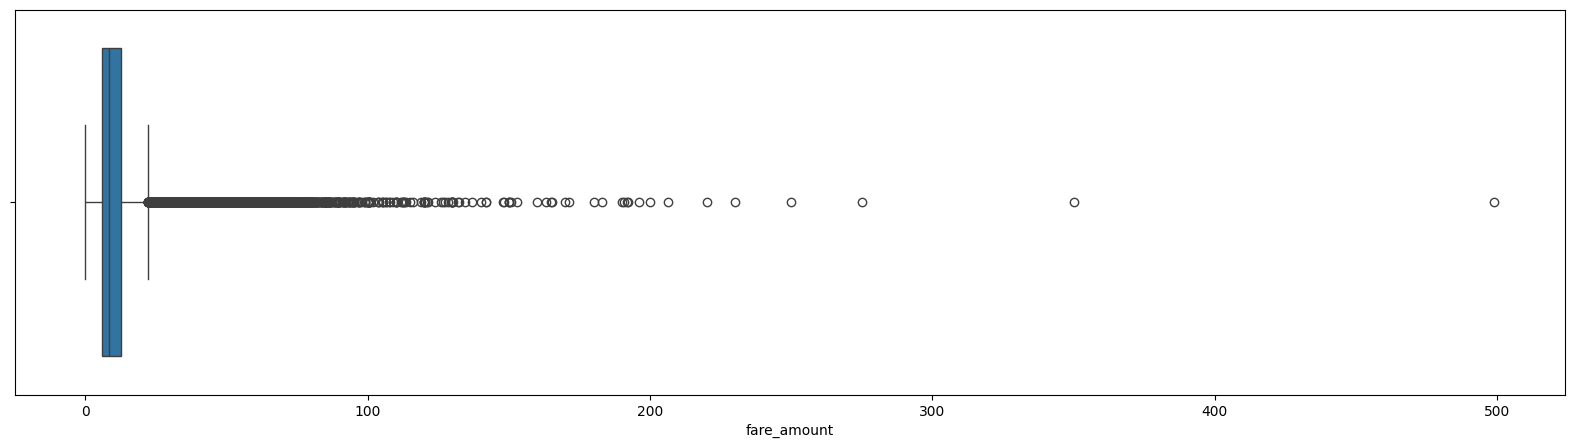

In [94]:
plt.figure(figsize=(20,5))
sns.boxplot(x=df["fare_amount"])
plt.show()

In [96]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

outliers = df[(df["fare_amount"]>upper) | (df["fare_amount"]<lower) ]


In [97]:
print("Length of Outliers",len(outliers))

Length of Outliers 17121


In [99]:
print("Lower Limit : ", lower)
print("Upper Limit :", upper)
df.shape

Lower Limit :  -3.75
Upper Limit : 22.25


(199268, 10)

In [113]:
df = df[(df["fare_amount"]<= upper) & (df["fare_amount"]>=lower)]
df.shape

(182136, 10)

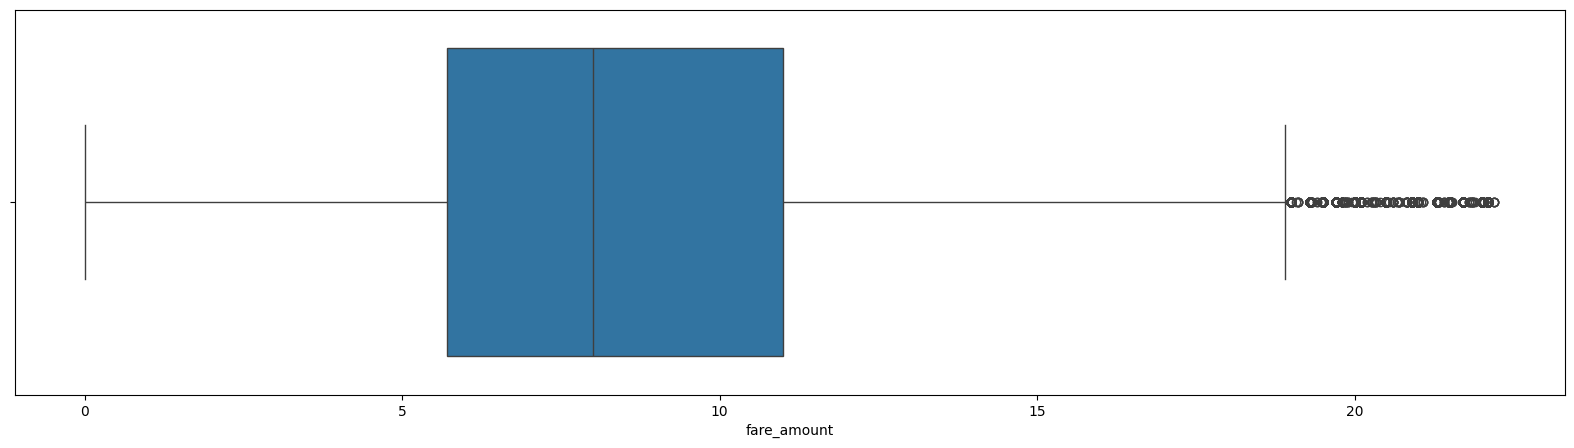

In [102]:
plt.figure(figsize=(20,5))
sns.boxplot(x=df["fare_amount"])
plt.show()




In [110]:
# Remove invalid geographical coordinates

df = df[
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180))
]

In [111]:
corr = df.corr(numeric_only=True)

<Axes: >

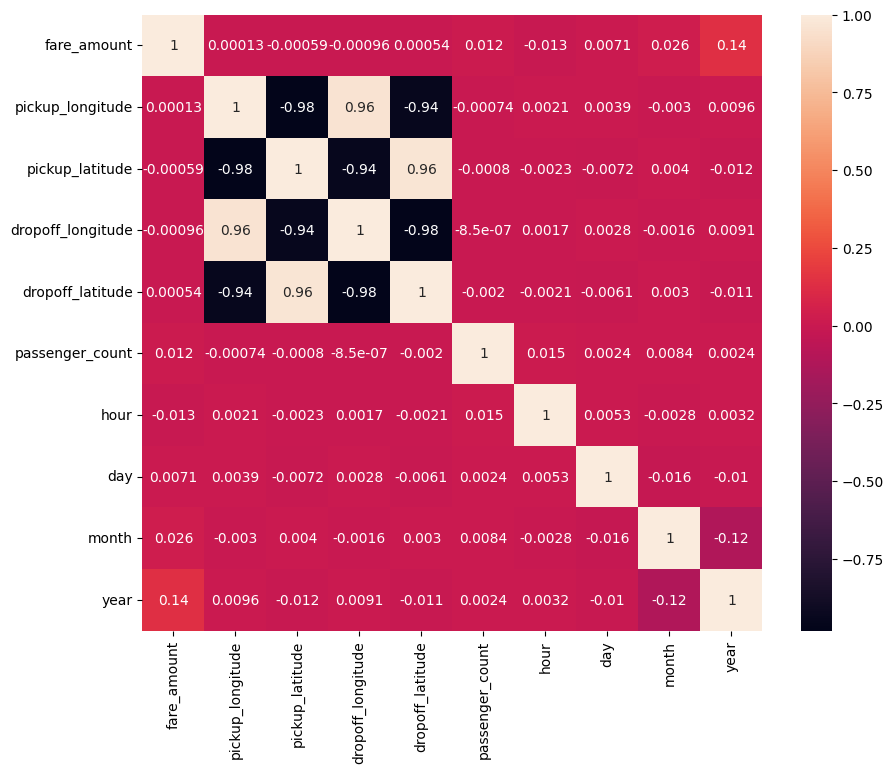

In [112]:
plt.figure(figsize = (10,8))
sns.heatmap(corr,annot=True)

In [123]:
X = df.drop("fare_amount", axis= 1)
y = df["fare_amount"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state = 42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (145708, 9)
Testing data: (36428, 9)


In [116]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

lr_model.fit(X_train,y_train)
lr_model_pred = lr_model.predict(X_test)

In [120]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators = 50,random_state=42)

rf.fit(X_train,y_train)
rf_model_pred = rf.predict(X_test)

In [124]:

from sklearn.metrics import r2_score, mean_squared_error

# Linear Regression evaluation
r2_lr = r2_score(y_test, lr_model_pred)

rmse_lr = np.sqrt(
    mean_squared_error(y_test,lr_model_pred)
)

# Random Forest evaluation
r2_rf = r2_score(y_test, rf_model_pred)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, rf_model_pred)
)

print("Linear Regression")
print("R2 Score:", r2_lr)
print("RMSE:", rmse_lr)

print("\nRandom Forest Regression")
print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)

Linear Regression
R2 Score: 0.019088568246451332
RMSE: 4.085366406102863

Random Forest Regression
R2 Score: 0.7488023120592107
RMSE: 2.0673972502644857
